In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

INCLUDE_CURRENT_PRICE = True   # False -> drop Price_in_Lakhs and Price_per_SqFt from features

In [2]:
df = pd.read_csv("real_estate_final.csv")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Corr(Future_Price_5Y, Price_in_Lakhs):",
      round(df["Future_Price_5Y"].corr(df["Price_in_Lakhs"]), 4))

Dataset Shape: (250000, 93)
Missing Values: 0
Corr(Future_Price_5Y, Price_in_Lakhs): 1.0


In [3]:
target = "Future_Price_5Y"

drop_cols = ["Future_Price_5Y", "Good_Investment", "Investment_Score", "ID"]
if not INCLUDE_CURRENT_PRICE:
    drop_cols += ["Price_in_Lakhs", "Price_per_SqFt"]

X = df.drop(columns=drop_cols, errors="ignore")
y = df[target]

print("X Shape:", X.shape, "| y Shape:", y.shape)

X Shape: (250000, 90) | y Shape: (250000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (200000, 90) | X_test: (50000, 90)


In [5]:
numeric_features = [
    col for col in [
        "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
        "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
        "Nearby_Schools", "Nearby_Hospitals", "Amenity_Density_Score",
        "Locality_Frequency"
    ]
    if col in X_train.columns
]

X_train = X_train.copy()
X_test = X_test.copy()
X_train[numeric_features] = X_train[numeric_features].astype(float)
X_test[numeric_features] = X_test[numeric_features].astype(float)

# Fit the scaler on TRAIN only, then apply to test (no leakage)
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Scaled", len(numeric_features), "numeric features.")

Scaled 12 numeric features.


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Linear Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.
XGBoost trained.


In [7]:
results, predictions = [], {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values(by="R2", ascending=False)
    .reset_index(drop=True)
)
results_df

,Model,MSE,RMSE,MAE,R2
0,Linear Regression,1.179289e-24,1.085951e-12,9.312014e-13,1.000000
1,Random Forest,1.108327e-05,3.329154e-03,2.027801e-03,1.000000
2,Decision Tree,2.670521e-03,5.167709e-02,4.449016e-02,1.000000
3,XGBoost,6.629573e-01,8.142219e-01,7.036928e-01,0.999985
4,Gradient Boosting,2.019546e+00,1.421107e+00,1.075081e+00,0.999953


In [8]:
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]
y_pred_best = predictions[best_model_name]

print("Best model on this test split:", best_model_name)
print(results_df.iloc[0])

Best model on this test split: Linear Regression
Model    Linear Regression
MSE                    0.0
RMSE                   0.0
MAE                    0.0
R2                     1.0
Name: 0, dtype: object


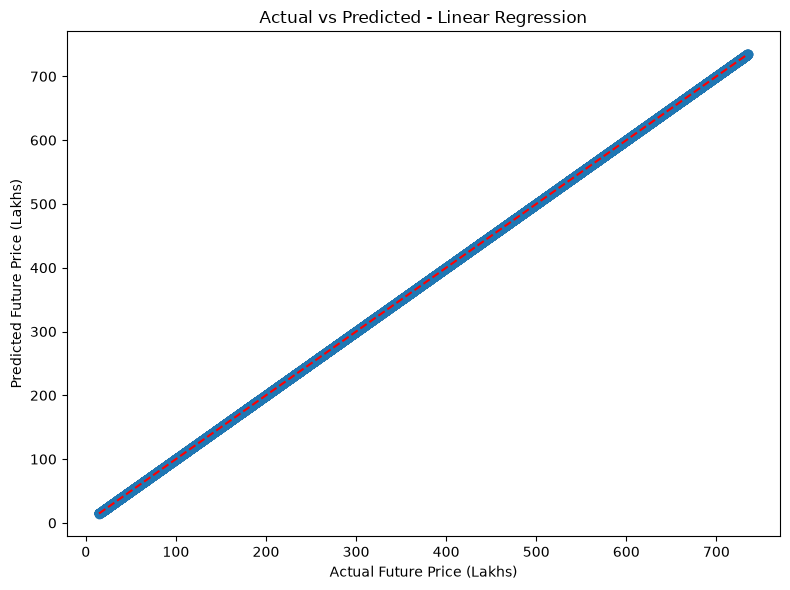

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Future Price (Lakhs)")
plt.ylabel("Predicted Future Price (Lakhs)")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.tight_layout()
plt.show()

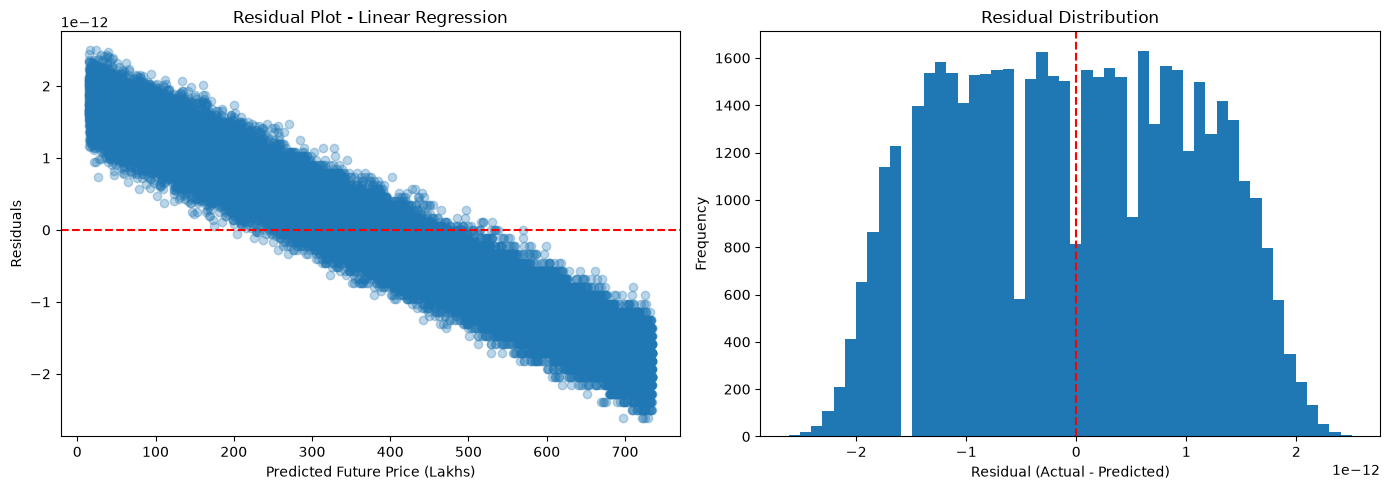

In [10]:
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_best, residuals, alpha=0.3)
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_xlabel("Predicted Future Price (Lakhs)")
axes[0].set_ylabel("Residuals")
axes[0].set_title(f"Residual Plot - {best_model_name}")

axes[1].hist(residuals, bins=50)
axes[1].axvline(0, color="r", linestyle="--")
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

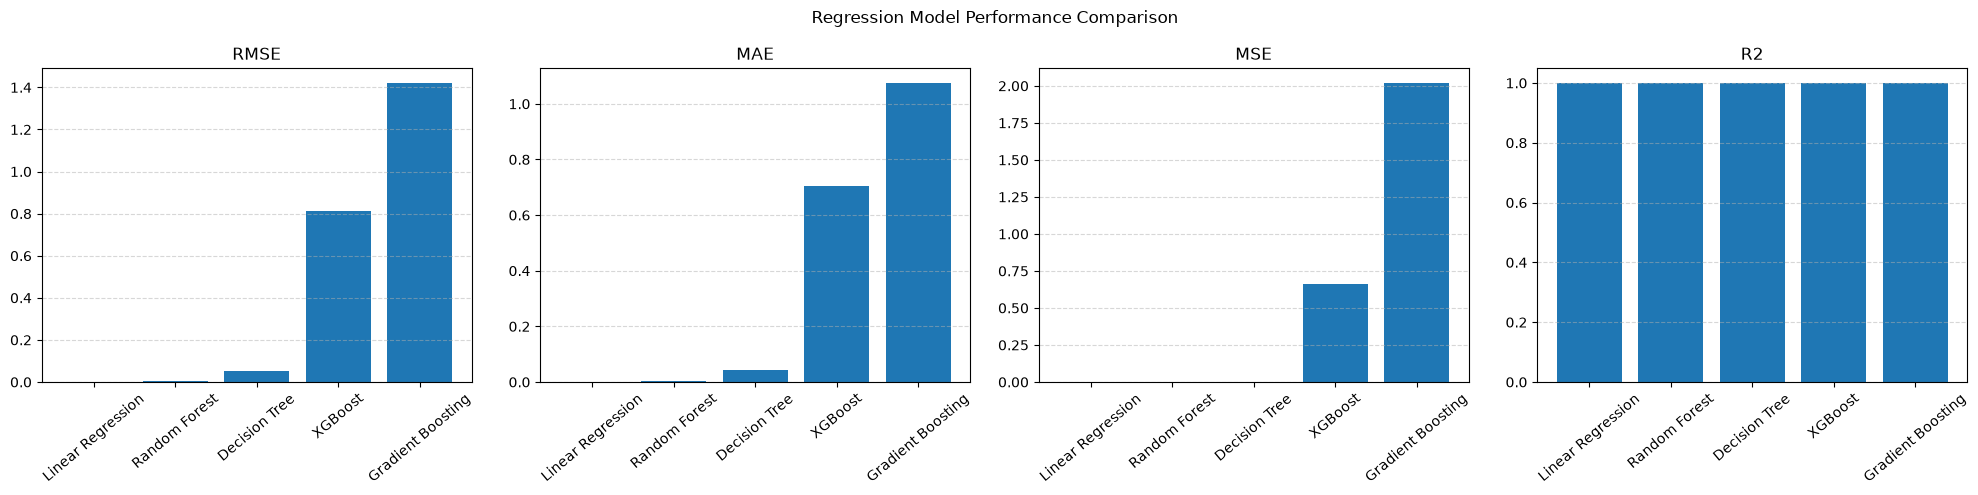

In [11]:
# Metrics live on different scales, so each gets its own panel
metrics = ["RMSE", "MAE", "MSE", "R2"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, metric in zip(axes, metrics):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Regression Model Performance Comparison")
plt.tight_layout()
plt.show()

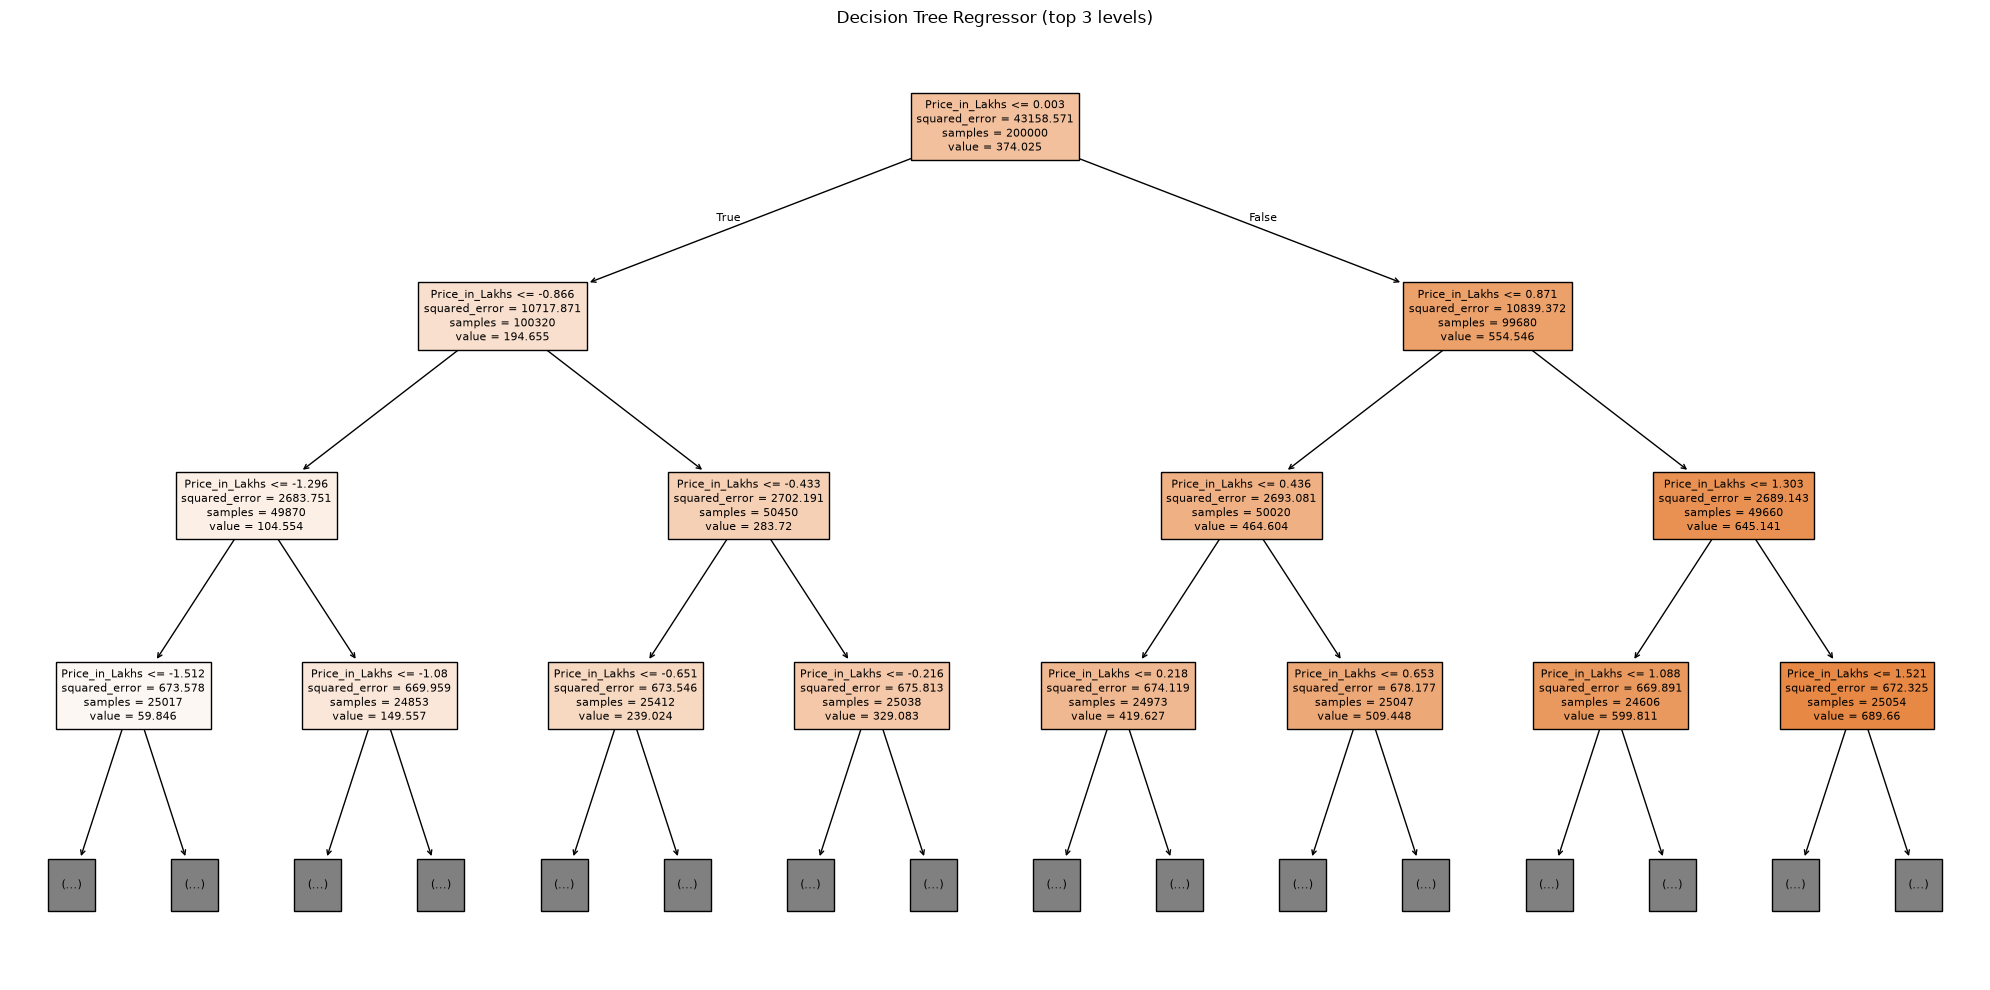

In [12]:
plt.figure(figsize=(20, 10))

plot_tree(
    models["Decision Tree"],
    feature_names=X_train.columns.tolist(),
    filled=True, max_depth=3, fontsize=8
)

plt.title("Decision Tree Regressor (top 3 levels)")
plt.tight_layout()
plt.show()

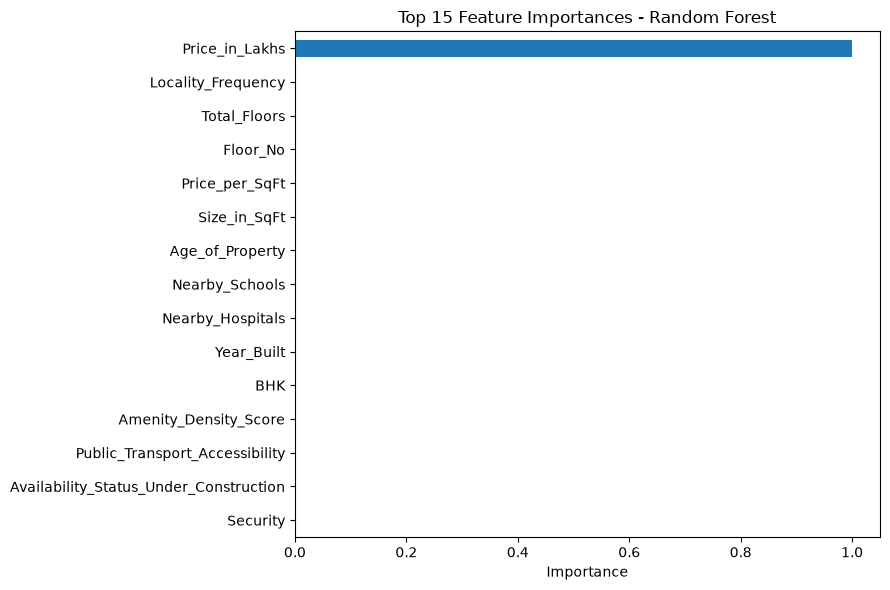

In [13]:
importance = (
    pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
    .head(15)
)

importance[::-1].plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [14]:
SAVE_DIR = "saved_models/regression"
os.makedirs(SAVE_DIR, exist_ok=True)

# Every model is saved under its OWN name
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, f"{SAVE_DIR}/{filename}")

# Preprocessing artifacts used by app.py
joblib.dump(scaler, f"{SAVE_DIR}/scaler.pkl")
joblib.dump(numeric_features, f"{SAVE_DIR}/numeric_features.pkl")
joblib.dump(X_train.columns.tolist(), f"{SAVE_DIR}/feature_columns.pkl")
results_df.to_csv(f"{SAVE_DIR}/metrics.csv", index=False)

print("Saved files:", sorted(os.listdir(SAVE_DIR)))

Saved files: ['decision_tree.pkl', 'feature_columns.pkl', 'gradient_boosting.pkl', 'linear_regression.pkl', 'metrics.csv', 'numeric_features.pkl', 'random_forest.pkl', 'scaler.pkl', 'xgboost.pkl']
